# 23 — Regional currency-risk pricing: USD and EUR investors

Add explicit currency risk for **Poland, Czechia, Romania, Sweden and Hungary** on the identical
frozen **October 2014–September 2026** sample (**144 months**). Fit both **scalar and diagonal
BEKK**, comparing zero versus freely estimated constant FX prices within the same five-series
system: **40 joint fits**. World and US/national local prices remain constant; equity alphas are zero.

Use the **corrected paper-style FX means** already adopted in the Hungarian analysis (notebook 08
onward), without VAR corrections or time-varying instruments. This avoids repeating the earlier
VAR(6) adaptation and retains a parsimonious 20–30 parameters. This remains an application to public
spot FX and equity proxies, rather than an exact reproduction of every measurement in the paper.

Use the existing **Miniconda base** kernel. Read frozen files only; no downloads, API keys,
installation, custom kernel or changes to previous research outputs.

In [1]:
# Fixed common sample; adjustable numerical and diagnostic controls.
START_DYNAMICS = [(0.05, 0.90), (0.10, 0.70)]
MAX_ITER = 1800
TEST_LAGS = 12
HAC_LAGS = (0, 3, 6, 12)
REUSE_FITS = True
MODEL_VERSION = "regional_constant_currency_priced_means_v1"
PREVIOUS_MANIFEST_SHA = "ddbf6e9b40e113fd32d0fef6ae646211f26d5337f1d3ec644e24e236a441e794"
LOCK_HASHES = {
    "regional_dataset_inputs.json": "0ceeef569dc4513d8534faf346509b22245db7ebff63abeb77044fc1474be208",
    "research_synthesis_inputs.json": "4fc2f36215746dd0ad0fef3ac41d8953f4abc6f1a3a36b526813437a26f081ee",
}

from pathlib import Path
from io import BytesIO
import hashlib, importlib, importlib.metadata, json, os, platform, sys
ROOT = Path.cwd()
os.environ.setdefault("MPLCONFIGDIR", str(ROOT/".cache"/"matplotlib"))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm, chi2
from packaging.version import Version
versions = {p: importlib.metadata.version(p) for p in
            ["numpy", "pandas", "scipy", "statsmodels", "matplotlib", "ipykernel"]}
if Version(versions["statsmodels"]) < Version("0.15.0"):
    raise RuntimeError("Use the base environment already used for notebooks 20–22 (statsmodels 0.15.0 or later).")
if "statsmodels" in sys.modules and sys.modules["statsmodels"].__version__ != versions["statsmodels"]:
    raise RuntimeError("Restart the existing base kernel to discard stale statsmodels imports.")
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch
from statsmodels.stats.multitest import multipletests
from IPython.display import display, Markdown
import pricing_robustness as core
importlib.reload(core)
import regional_currency_pricing as engine
importlib.reload(engine)

NAMES = {"PL": "Poland", "CZ": "Czechia", "RO": "Romania", "SE": "Sweden", "HU": "Hungary"}
LOCAL_CURRENCIES = {"PL": "PLN", "CZ": "CZK", "RO": "RON", "SE": "SEK", "HU": "HUF"}
COUNTRY_ORDER, CURRENCIES, COVARIANCES = ["HU", "PL", "CZ", "RO", "SE"], ["USD", "EUR"], ["scalar", "diagonal"]
ASSETS = ["World", "US", "National", "National FX", "Other FX"]
COLORS = {"PL": "#285f9e", "CZ": "#2a8a70", "RO": "#9469ad", "SE": "#b77d13", "HU": "#c4483b"}
PREVIOUS = ROOT/"output"/"22_regional_covariance_sensitivity"/"2014-10_2026-09"
OUT = ROOT/"output"/"23_regional_currency_risk"/"2014-10_2026-09"
OUT.mkdir(parents=True, exist_ok=True)
def sha(raw): return hashlib.sha256(raw).hexdigest()
engine_hashes = {name: sha((ROOT/name).read_bytes()) for name in
    ["regional_currency_pricing.py", "pricing_robustness.py", "regional_pricing_baseline.py", "regional_covariance_sensitivity.py"]}
assert 2 <= TEST_LAGS <= 24 and tuple(HAC_LAGS) == (0, 3, 6, 12)
assert all(a > 0 and b > 0 and a+b < 1 for a, b in START_DYNAMICS)
plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.alpha": .18})
pd.set_option("display.max_columns", 14)
print("Python:", sys.executable)
print("Packages:", versions)
print("Currency engine SHA-256:", engine_hashes["regional_currency_pricing.py"])

Python: /Users/lajosgalambos/miniconda3/bin/python
Packages: {'numpy': '2.4.4', 'pandas': '3.0.2', 'scipy': '1.17.1', 'statsmodels': '0.15.0', 'matplotlib': '3.10.8', 'ipykernel': '7.2.0'}
Currency engine SHA-256: 9f571b7fffdaebd1e02f95aaeaac749beae74b4cfb94c507b2bcacf85bf0ee8d


## 1. Verify the frozen common sample and independent FX basis

Verify the pinned notebook-22 manifest, every file it protects, its own outputs and the two original
dataset locks. The previous three-equity results are preserved as context, not reused as five-series
estimates. Read monthly excess equity log returns and spot log changes in **percentage points**.

USD uses national-currency appreciation against USD plus EUR appreciation against USD. EUR uses
national-currency appreciation against EUR plus USD appreciation against EUR. There are exactly
two independent FX factors; adding the third bilateral rate would create linear dependence.
Check factor rank, covariance conditioning and the observed USD/EUR conversion, including cash.
Romania's relatively small RON/EUR volatility is measured, never filled or artificially enlarged.

In [2]:
def verify_inputs():
    raw = (PREVIOUS/"estimation_manifest.json").read_bytes()
    if sha(raw) != PREVIOUS_MANIFEST_SHA: raise ValueError("Notebook-22 manifest changed.")
    previous = json.loads(raw)
    assert previous["input_locks"] == LOCK_HASHES
    assert (previous["first"], previous["last"], previous["observations_per_fit"]) == ("2014-10", "2026-09", 144)
    expected = previous["input_file_hashes"].copy()
    for name, checksum in previous["outputs"].items():
        expected[(PREVIOUS/name).relative_to(ROOT).as_posix()] = checksum
    expected[(PREVIOUS/"estimation_manifest.json").relative_to(ROOT).as_posix()] = PREVIOUS_MANIFEST_SHA
    expected[previous["engine"]] = previous["engine_sha256"]
    locks = {}
    for name, checksum in LOCK_HASHES.items():
        content = (ROOT/name).read_bytes()
        if sha(content) != checksum: raise ValueError(f"Changed input lock: {name}")
        locks[name] = json.loads(content)
    for path, checksum in expected.items():
        if sha((ROOT/path).read_bytes()) != checksum: raise ValueError(f"Changed frozen input: {path}")
    regional = locks["regional_dataset_inputs.json"]
    assert sha((ROOT/regional["root"]/"manifest.json").read_bytes()) == regional["manifest_sha256"]
    return locks, expected

locks, input_hashes = verify_inputs()
regional = locks["regional_dataset_inputs.json"]
assert (regional["common_start"], regional["common_end"], regional["common_months"]) == ("2014-10", "2026-09", 144)
months = pd.period_range("2014-10", "2026-09", freq="M", name="month")
frames, samples, scales, source_hashes, audit_rows = {}, {}, {}, {}, []
for country in COUNTRY_ORDER:
    for currency in CURRENCIES:
        path = ROOT/regional["root"]/"common"/f"{country}_{currency}.csv"
        raw = path.read_bytes()
        assert sha(raw) == input_hashes[path.relative_to(ROOT).as_posix()]
        d = pd.read_csv(BytesIO(raw), index_col=0, float_precision="round_trip")
        d.index = pd.PeriodIndex(d.index, freq="M", name="month")
        assert d.index.equals(months) and np.isfinite(d.to_numpy()).all() and d.flag_known_index_backcast.sum() == 0
        for asset in ["world", "us", "local"]:
            np.testing.assert_allclose(d[f"rx_{asset}"], d[f"r_{asset}"]-d.rf, atol=1e-12, rtol=0)
        y = d[["rx_world", "rx_us", "rx_local", "fx_local", "fx_other"]].to_numpy()*100
        scale = y.std(axis=0, ddof=1)
        correlation = np.cov(y, rowvar=False)/np.outer(scale, scale)
        assert (scale > 0).all() and np.linalg.eigvalsh(correlation).min() > 0 and np.linalg.matrix_rank(y-y.mean(axis=0)) == 5
        key = (country, currency)
        frames[key], samples[key], scales[key], source_hashes[key] = d, y, scale, sha(raw)
        np.testing.assert_array_equal(y[:, [0, 1, 4]], samples[("HU", currency)][:, [0, 1, 4]])
        audit_rows.append({"country": country, "name": NAMES[country], "perspective": currency,
            "first": str(months[0]), "last": str(months[-1]), "months": len(y), "rank": 5,
            "min_correlation_eigenvalue": np.linalg.eigvalsh(correlation).min(), "correlation_condition": np.linalg.cond(correlation),
            "national_FX_sd_pp": scale[3], "national_FX_currency": LOCAL_CURRENCIES[country],
            "other_FX_currency": "EUR" if currency == "USD" else "USD"})
transform = np.eye(5)
transform[:3, 4], transform[3, 4], transform[4, 4] = -1., -1., -1.
for country in COUNTRY_ORDER:
    converted = samples[(country, "USD")]@transform.T
    converted[:, :3] += ((frames[(country, "USD")].rf-frames[(country, "EUR")].rf)*100).to_numpy()[:, None]
    np.testing.assert_allclose(converted, samples[(country, "EUR")], atol=1e-10, rtol=0)
input_audit = pd.DataFrame(audit_rows)
display(input_audit.set_index(["name", "perspective"])[["months", "rank", "correlation_condition", "national_FX_sd_pp", "other_FX_currency"]].round(4))
print("Verified", len(input_hashes), "protected files and all ten five-series input systems.")

months  rank  correlation_condition  national_FX_sd_pp  \
name    perspective                                                           
Hungary USD             144     5               177.8975             3.0207   
        EUR             144     5               123.6042             1.7874   
Poland  USD             144     5               196.7334             2.9611   
        EUR             144     5               135.7310             1.4953   
Czechia USD             144     5               218.7463             2.6464   
        EUR             144     5               152.3439             1.1305   
Romania USD             144     5               168.0376             2.1759   
        EUR             144     5               110.8968             0.5283   
Sweden  USD             144     5               242.4797             2.9674   
        EUR             144     5               174.9449             1.7097   

                    other_FX_currency  
name    perspective                    
Hungary USD                       EUR  
        EUR                       USD  
Poland  USD                       EUR  
        EUR                       USD  
Czechia USD                       EUR  
        EUR                       USD  
Romania USD                       EUR  
        EUR                       USD  
Sweden  USD                       EUR  
        EUR                       USD

Verified 960 protected files and all ten five-series input systems.


## 2. Pricing restrictions, corrected FX means and covariance

For equities **World, US, national market**, use the world covariance term, the two FX covariance
terms and own-variance local terms for US/national equity only. For the two **FX factors**, use the
same three common priced covariance terms, without a local variance term:

$$E_{t-1}[y_{i,t}]=\lambda_W H_{iW,t}+\lambda_F H_{iF,t}+\lambda_O H_{iO,t}
+\mathbf{1}_{i=US}\lambda_{US}H_{US,US,t}+\mathbf{1}_{i=L}\lambda_LH_{L,L,t}.$$

The formula applies to all five rows; the indicator terms vanish in the world/FX equations. Here
F denotes national FX, O the other FX factor, and L national equity. All prices are **constant and
unrestricted in sign**. `no_fx` fixes only the two FX prices to zero; `with_fx` frees them in every
mean equation. There are **no free equity alphas, FX intercepts or VAR correction coefficients**.

This is the corrected paper-style FX restriction used in [notebook 08](08_specification_audit.ipynb),
applied to the frozen **spot log changes** as in our Hungarian analysis. It does not manufacture
currency-deposit excess returns, forward returns or national cash rates. A formal interpretation
remains conditional on these measurement choices, the two-FX basis and the covariance specification.

Both covariance models use a free positive-definite intercept, stationary innovation initialization
and nonnegative diagonal shock/persistence coefficients. Scalar BEKK shares one dynamic pair
across all five series; diagonal BEKK has five pairs. Parameters: **20/22** for scalar no-FX/with-FX,
**28/30** for diagonal. The scalar restriction is nested by equating all pairs. The five-series
likelihoods are **not comparable by AIC/BIC with notebook 22's three-series likelihoods**.

In [3]:
check_rows = []
for key, y in samples.items():
    for covariance in COVARIANCES:
        for with_fx in [False, True]:
            theta = engine.initial_theta(y, scales[key], with_fx, covariance)
            theta += np.linspace(-.01, .015, len(theta))
            analytic = engine.objective(theta, y[:35], scales[key], with_fx, covariance)[1]
            numeric = engine.numerical_gradient(lambda t: engine.objective(t, y[:35], scales[key], with_fx, covariance)[0], theta)
            np.testing.assert_allclose(analytic, numeric, atol=5e-6, rtol=5e-5)
            f = engine.filter_model(theta, y, scales[key], with_fx, covariance)
            expected = sum(f["prices"][p]*f["H"][:, :, factor] for p, factor in [(0, 0), (3, 3), (4, 4)])
            expected[:, 1] += f["prices"][1]*f["H"][:, 1, 1]
            expected[:, 2] += f["prices"][2]*f["H"][:, 2, 2]
            np.testing.assert_allclose(f["mu"], expected, atol=1e-12, rtol=0)
            assert np.linalg.eigvalsh(f["H"]).min() > 0
            if not with_fx:
                nested = engine.filter_model(engine.expand(theta, False), y, scales[key], True, covariance)
                for name in ["losses", "mu", "H"]: np.testing.assert_allclose(f[name], nested[name], atol=1e-12, rtol=0)
            if covariance == "scalar":
                nested = engine.filter_model(engine.expand_scalar(theta), y, scales[key], with_fx, "diagonal")
                for name in ["losses", "mu", "H"]: np.testing.assert_allclose(f[name], nested[name], atol=1e-12, rtol=0)
            check_rows.append({"country": key[0], "perspective": key[1], "covariance": covariance,
                "with_FX": with_fx, "parameters": len(theta), "max_gradient_error": np.abs(analytic-numeric).max()})
checks = pd.DataFrame(check_rows)
display(checks.groupby(["covariance", "with_FX"])[["parameters", "max_gradient_error"]].max())
print("All 40 gradient, corrected mean, covariance-positivity and exact-nesting checks pass.")

parameters  max_gradient_error
covariance with_FX                                
diagonal   False            28        3.903495e-08
           True             30        3.842982e-08
scalar     False            20        4.019365e-08
           True             22        4.219294e-08

All 40 gradient, corrected mean, covariance-positivity and exact-nesting checks pass.


## 3. Fit the nested five-series models from fixed starts

Start with two fixed covariance-dynamics moment starts. Add the corresponding fitted no-FX
restriction to each with-FX fit, and the corresponding scalar solution to each diagonal fit.
Retain all 144 observations: no mean lags or burn-in trimming is needed for this specification.

Require optimizer success and a projected score gradient below 0.0001 (the box-constraint KKT
criterion from notebook 22); record raw and projected gradients. Bound solutions remain point
estimates with regular inference suppressed. A lower nonconverged candidate stops selection.
The selected optimum must beat each nested parent. Multiple starts do not prove a global optimum.

Cache keys include every model input, engine/dependency hash, optimizer setting, package version
and the exact starting vectors. Re-filter cached fits and check bounds/gradients before reuse.
The corrected-mean filter reuses `pricing_robustness.py`; only the two fixed FX coordinates are
removed in the no-FX restriction. Earlier code and outputs are not rewritten.

In [4]:
fits, start_rows = {}, []
for key, y in samples.items():
    country, currency = key
    for covariance in COVARIANCES:
        for model, with_fx in [("no_fx", False), ("with_fx", True)]:
            print(f"{NAMES[country]} · {currency} · {covariance} · {model}", flush=True)
            starts = [engine.initial_theta(y, scales[key], with_fx, covariance, a, b) for a, b in START_DYNAMICS]
            labels, parents = [f"moment dynamics {a:g}/{b:g}" for a, b in START_DYNAMICS], []
            if covariance == "diagonal":
                parent = (*key, "scalar", model)
                starts.insert(0, engine.expand_scalar(fits[parent]["theta"]))
                labels.insert(0, "corresponding scalar solution"); parents.append(parent)
            if with_fx:
                parent = (*key, covariance, "no_fx")
                starts.insert(0, engine.expand(fits[parent]["theta"], False))
                labels.insert(0, "nested no-FX solution"); parents.append(parent)
            config = {"version": MODEL_VERSION, "engines": engine_hashes, "country": country,
                "perspective": currency, "covariance": covariance, "model": model, "source_sha256": source_hashes[key],
                "previous_manifest_sha256": PREVIOUS_MANIFEST_SHA, "first": str(months[0]), "last": str(months[-1]),
                "starts": START_DYNAMICS, "start_labels": labels, "start_hashes": [sha(t.tobytes()) for t in starts],
                "max_iter": MAX_ITER, "packages": versions, "python": platform.python_version()}
            fingerprint = sha(json.dumps(config, sort_keys=True).encode()+y.tobytes())
            path = OUT/f"fit_{country}_{currency}_{covariance}_{model}.json"
            record = json.loads(path.read_text()) if REUSE_FITS and path.exists() else None
            limits = engine.bounds(with_fx, covariance)
            if record is not None and record.get("fingerprint") == fingerprint:
                theta = np.asarray(record["theta"])
                value, gradient = engine.objective(theta, y, scales[key], with_fx, covariance)
                projected = engine.projected_gradient(theta, gradient, limits)
                valid = (record.get("optimizer_success") and np.isfinite(value) and abs(value-record["mean_nll"]) < 1e-8
                    and np.abs(projected).max() < 1e-4 and ((theta >= limits[:, 0]) & (theta <= limits[:, 1])).all())
                if not valid: record = None
            else: record = None
            if record is None:
                best, runs = engine.fit_starts(y, scales[key], with_fx, covariance, starts, MAX_ITER)
                record = {"fingerprint": fingerprint, "config": config, "theta": best.x.tolist(),
                    "mean_nll": float(best.fun), "optimizer_success": bool(best.success), "starts": runs}
                temp = path.with_suffix(".tmp")
                temp.write_text(json.dumps(record, indent=2, sort_keys=True)+"\n"); temp.replace(path)
            else: print("  verified cached fit", flush=True)
            theta = np.asarray(record["theta"])
            f = engine.filter_model(theta, y, scales[key], with_fx, covariance)
            assert np.linalg.eigvalsh(f["H"]).min() > 0
            for parent in parents: assert f["losses"].sum() <= fits[parent]["filter"]["losses"].sum()+1e-5
            fits[(*key, covariance, model)] = {"theta": theta, "filter": f, "with_fx": with_fx,
                "y": y, "scales": scales[key], "record": record}
            start_rows.extend({"country": country, "perspective": currency, "covariance": covariance,
                "model": model, "start_label": labels[r["start"]-1], **r} for r in record["starts"])
start_columns = ["country", "perspective", "covariance", "model", "start_label", "start", "success", "mean_nll",
    "max_abs_gradient", "max_projected_gradient", "iterations", "refined", "message"]
starts_table = pd.DataFrame(start_rows, columns=start_columns)
display(starts_table.groupby(["country", "perspective", "covariance", "model"]).agg(starts=("start", "count"),
    successes=("success", "sum"), best_mean_NLL=("mean_nll", "min"), worst_mean_NLL=("mean_nll", "max"),
    worst_projected_gradient=("max_projected_gradient", "max")).round(7))

Hungary · USD · scalar · no_fx


  start 1: success=True, NLL=10.985021467, raw=6.60e-07, projected=6.60e-07, iterations=107


  start 2: success=True, NLL=10.985021467, raw=1.23e-06, projected=1.23e-06, iterations=82


Hungary · USD · scalar · with_fx


  start 1: success=True, NLL=10.971413480, raw=6.11e-07, projected=6.11e-07, iterations=94


  start 2: success=True, NLL=10.971413480, raw=3.98e-07, projected=3.98e-07, iterations=141


... (151 outputs left out)

  start 2: success=True, NLL=10.204166728, raw=8.27e-07, projected=8.27e-07, iterations=282


  start 3: success=True, NLL=10.204166728, raw=1.53e-06, projected=1.53e-06, iterations=437


  start 4: success=True, NLL=10.204166728, raw=6.24e-07, projected=6.24e-07, iterations=323


starts  successes  best_mean_NLL  \
country perspective covariance model                                       
CZ      EUR         diagonal   no_fx         3          3      10.030124   
                               with_fx       4          4      10.025659   
                    scalar     no_fx         2          2      10.079927   
                               with_fx       3          3      10.079693   
        USD         diagonal   no_fx         3          3      10.074254   
                               with_fx       4          4      10.063885   
                    scalar     no_fx         2          2      10.089892   
                               with_fx       3          3      10.082367   
HU      EUR         diagonal   no_fx         3          3      10.936661   
                               with_fx       4          4      10.924992   
                    scalar     no_fx         2          2      10.976233   
                               with_fx       3          3      10.968461   
        USD         diagonal   no_fx         3          3      10.918997   
                               with_fx       4          4      10.904542   
                    scalar     no_fx         2          2      10.985022   
                               with_fx       3          3      10.971414   
PL      EUR         diagonal   no_fx         3          3      10.413241   
                               with_fx       4          4      10.405429   
                    scalar     no_fx         2          2      10.455899   
                               with_fx       3          3      10.450403   
        USD         diagonal   no_fx         3          3      10.401721   
                               with_fx       4          4      10.384142   
                    scalar     no_fx         2          2      10.465141   
                               with_fx       3          3      10.452718   
RO      EUR         diagonal   no_fx         3          3       9.803274   
                               with_fx       4          4       9.770592   
                    scalar     no_fx         2          2       9.826477   
                               with_fx       3          3       9.794958   
        USD         diagonal   no_fx         3          3       9.743259   
                               with_fx       4          4       9.701353   
                    scalar     no_fx         2          2       9.838044   
                               with_fx       3          3       9.797538   
SE      EUR         diagonal   no_fx         3          3      10.212521   
                               with_fx       4          4      10.204167   
                    scalar     no_fx         2          2      10.246233   
                               with_fx       3          3      10.236303   
        USD         diagonal   no_fx         3          3      10.229899   
                               with_fx       4          4      10.213246   
                    scalar     no_fx         2          2      10.257063   
                               with_fx       3          3      10.236943   

                                        worst_mean_NLL  \
country perspective covariance model                     
CZ      EUR         diagonal   no_fx         10.034611   
                               with_fx       10.032789   
                    scalar     no_fx         10.079927   
                               with_fx       10.079693   
        USD         diagonal   no_fx         10.075115   
                               with_fx       10.070742   
                    scalar     no_fx         10.089892   
                               with_fx       10.082367   
HU      EUR         diagonal   no_fx         10.936700   
                               with_fx       10.925014   
                    scalar     no_fx         10.976233   
                               with_fx       10.968461   
        USD         diagonal   no_f

## 4. Numerical regularity, robust uncertainty and zero-FX-price tests

Use the full joint robust QML sandwich (score OPG, lag 0), with fixed Bartlett score-HAC lags
**3, 6 and 12**. These alter uncertainty, not point estimates. Check two Hessian steps and retain
parameter-bound, curvature/condition, Hessian-stability and price-SE-stability gates. Record reasons
for unavailable inference; do not read missing p-values as non-rejections. Inspect weak FX-price
identification, particularly when a currency factor has low variance.

Under with-FX, test **both FX prices jointly zero**, and local equity prices separately/jointly.
Individual price intervals/p-values and all bandwidth tests are saved. These are exploratory
asymptotic tests without price-test multiplicity correction. HAC cannot repair an inadequate mean
or covariance restriction. These tests do not compare countries' coefficients or treat USD/EUR as
independent replications. Do not report an ordinary Gaussian LR chi-square p-value under QML.

In [5]:
fit_rows, price_rows, test_rows, inference_rows, boundary_rows, dynamics_rows = [], [], [], [], [], []
for (country, currency, covariance, model), fit in fits.items():
    theta, f, y, with_fx = fit["theta"], fit["filter"], fit["y"], fit["with_fx"]
    info = engine.inference(theta, y, fit["scales"], with_fx, covariance, f, HAC_LAGS)
    fit["inference"] = info
    tags = {"country": country, "perspective": currency, "covariance": covariance, "model": model}
    labels = ["World price scaled", "US local price scaled", "National price scaled", "National FX price scaled", "Other FX price scaled"][:5 if with_fx else 3]
    labels += [f"{'log ' if i == j else ''}C[{i+1},{j+1}]" for i, j in zip(*engine.TRI)]
    labels += [f"{asset} {parameter} logit" for asset in (ASSETS if covariance == "diagonal" else ["Shared"]) for parameter in ["alpha", "beta"]]
    limits = engine.bounds(with_fx, covariance)
    distance = np.minimum(theta-limits[:, 0], limits[:, 1]-theta)
    boundary_rows.extend({**tags, "parameter": label, "coordinate": theta[j], "lower": limits[j, 0],
        "upper": limits[j, 1], "distance_to_bound": distance[j], "near_bound": bool(distance[j] < 1e-4)} for j, label in enumerate(labels))
    gradient = f["scores"].mean(axis=0)
    LL = -f["losses"].sum()
    fit_rows.append({**tags, "n": len(y), "parameters": len(theta), "loglik": LL, "AIC": -2*LL+2*len(theta),
        "BIC": -2*LL+np.log(len(y))*len(theta), "max_abs_gradient": np.abs(gradient).max(),
        "max_projected_gradient": np.abs(engine.projected_gradient(theta, gradient, limits)).max(),
        "min_H_eigenvalue": np.linalg.eigvalsh(f["H"]).min(),
        "bound_parameters": "; ".join(label for j, label in enumerate(labels) if distance[j] < 1e-4),
        **{name: info[name] for name in ["Hessian_min_eigenvalue", "Hessian_condition", "Hessian_step_difference", "min_distance_to_bounds"]}})
    for j, asset in enumerate(ASSETS):
        dynamics_rows.append({**tags, "asset": asset, "alpha": f["alpha"][j], "beta": f["beta"][j], "persistence": f["alpha"][j]+f["beta"][j]})
    for lag, estimate in info["estimates"].items():
        ready, V = estimate["ready"], estimate["covariance"]
        inference_rows.append({**tags, "HAC_lag": lag, "ready": ready, "reason": estimate["reason"],
            "price_SE_step_difference": estimate["price_SE_step_difference"]})
        for j, risk in enumerate(["World", "US local", "National local", "National FX", "Other FX"][:5 if with_fx else 3]):
            value, se = f["prices"][j], engine.PRICE_SCALE*np.sqrt(V[j, j]) if ready else np.nan
            price_rows.append({**tags, "risk": risk, "HAC_lag": lag, "estimate": value, "robust_se": se,
                "p_value": 2*norm.sf(abs(value/se)) if ready else np.nan, "ci95_low": value-1.96*se,
                "ci95_high": value+1.96*se, "inference_ready": ready, "reason": estimate["reason"]})
        restrictions = [("Both local prices zero", [1, 2]), ("National local price zero", [2]), ("US local price zero", [1])]
        if with_fx: restrictions = [("FX prices jointly zero", [3, 4])]+restrictions
        for name, ids in restrictions:
            variance, value = V[np.ix_(ids, ids)], theta[ids]
            valid = ready and np.linalg.eigvalsh(variance).min() > 0 and np.linalg.cond(variance) < 1e9
            statistic = value@np.linalg.solve(variance, value) if valid else np.nan
            test_rows.append({**tags, "HAC_lag": lag, "restriction": name, "Wald_statistic": statistic, "df": len(ids),
                "p_value": chi2.sf(statistic, len(ids)) if valid else np.nan, "inference_ready": valid,
                "reason": estimate["reason"] if not ready or valid else "unstable restriction covariance"})
fit_table, price_table, tests, inference_audit, boundary_audit, dynamics = map(pd.DataFrame,
    [fit_rows, price_rows, test_rows, inference_rows, boundary_rows, dynamics_rows])
display(inference_audit.query("HAC_lag == 0").groupby(["covariance", "model", "ready", "reason"]).size().rename("systems"))
display(tests.query("restriction == 'FX prices jointly zero'").pivot(
    index=["country", "perspective", "covariance"], columns="HAC_lag", values="p_value").round(5))

covariance  model    ready  reason                                                           
diagonal    no_fx    False  parameter bound                                                       1
                            parameter bound; ill-conditioned curvature                            4
                            parameter bound; nonpositive curvature; ill-conditioned curvature     2
                     True   numerically ready                                                     3
            with_fx  False  parameter bound                                                       1
                            parameter bound; ill-conditioned curvature                            6
                     True   numerically ready                                                     3
scalar      no_fx    True   numerically ready                                                    10
            with_fx  True   numerically ready                                                    10
Name: 

HAC_lag                              0        3        6        12
country perspective covariance                                    
CZ      EUR         diagonal        NaN      NaN      NaN      NaN
                    scalar      0.97097  0.97425  0.97373  0.96959
        USD         diagonal    0.40821  0.42348  0.42155  0.40597
                    scalar      0.36394  0.39533  0.39130  0.34537
HU      EUR         diagonal        NaN      NaN      NaN      NaN
                    scalar      0.39499  0.25534  0.20253  0.18363
        USD         diagonal        NaN      NaN      NaN      NaN
                    scalar      0.17067  0.15643  0.12760  0.08054
PL      EUR         diagonal        NaN      NaN      NaN      NaN
                    scalar      0.49562  0.40185  0.36399  0.41494
        USD         diagonal        NaN      NaN      NaN      NaN
                    scalar      0.18293  0.11493  0.08233  0.07900
RO      EUR         diagonal    0.02219  0.00125  0.00029  0.00010
                    scalar      0.02556  0.00090  0.00019  0.00009
        USD         diagonal        NaN      NaN      NaN      NaN
                    scalar      0.00366  0.00013  0.00002  0.00001
SE      EUR         diagonal    0.40063  0.32321  0.23170  0.16866
                    scalar      0.27928  0.21225  0.15654  0.10487
        USD         diagonal        NaN      NaN      NaN      NaN
                    scalar      0.08820  0.10550  0.08501  0.07377

## 5. Residual adequacy in the expanded system

Inspect all five marginal standardised innovations, their centered squares, ARCH effects and ten
Cholesky-whitened cross-products. Report raw and Holm-adjusted p-values. Each Holm family is
covariance × FX restriction × investor currency × diagnostic type: **25 marginal** or **50 pair**
series across five countries. Different fitted systems have different innovations despite sharing
some raw return series. There is no full estimated-GARCH degrees-of-freedom correction.

These are approximate screens. No rejection in 144 months is not model validation; FX mean or
covariance failures limit structural pricing interpretations. Keep the inflation carry/regime audit
for later stages; no inflation or regime instrument enters this constant-price likelihood.

In [6]:
residual_rows, cross_rows = [], []
for (country, currency, covariance, model), fit in fits.items():
    f = fit["filter"]
    tags = {"country": country, "perspective": currency, "covariance": covariance, "model": model}
    z = f["errors"]/np.sqrt(np.diagonal(f["H"], axis1=1, axis2=2))
    white = np.linalg.solve(np.linalg.cholesky(f["H"]), f["errors"][..., None])[..., 0]
    lb = lambda s: acorr_ljungbox(s, lags=[TEST_LAGS], return_df=True).lb_pvalue.iloc[0]
    for j, asset in enumerate(ASSETS):
        residual_rows.append({**tags, "asset": asset, "z_mean": z[:, j].mean(), "z_sd": z[:, j].std(ddof=1),
            "LB_z_p": lb(z[:, j]), "LB_z_squared_p": lb((z[:, j]-z[:, j].mean())**2),
            "ARCH_LM_p": het_arch(z[:, j], nlags=TEST_LAGS, ddof=0, result_object=False)[1]})
    for i, j in zip(*np.triu_indices(5, 1)):
        product = white[:, i]*white[:, j]
        cross_rows.append({**tags, "pair": f"{ASSETS[i]}/{ASSETS[j]}", "mean_whitened_product": product.mean(), "LB_product_p": lb(product)})
residuals, cross = pd.DataFrame(residual_rows), pd.DataFrame(cross_rows)
for frame, columns in [(residuals, ["LB_z_p", "LB_z_squared_p", "ARCH_LM_p"]), (cross, ["LB_product_p"])]:
    for _, idx in frame.groupby(["covariance", "model", "perspective"]).groups.items():
        for column in columns: frame.loc[idx, column+"_holm"] = multipletests(frame.loc[idx, column], method="holm")[1]
display(residuals.query("model == 'with_fx' and asset == 'National FX'").set_index(["country", "perspective", "covariance"])
    [["z_mean", "z_sd", "LB_z_p", "LB_z_p_holm", "ARCH_LM_p", "ARCH_LM_p_holm"]].round(5))

z_mean     z_sd   LB_z_p  LB_z_p_holm  \
country perspective covariance                                           
HU      USD         scalar     -0.01211  0.99689  0.98589      1.00000   
                    diagonal   -0.01383  0.99226  0.98182      1.00000   
        EUR         scalar     -0.01389  1.00700  0.68504      1.00000   
                    diagonal    0.00497  1.00808  0.78959      1.00000   
PL      USD         scalar     -0.01985  0.98872  0.95519      1.00000   
                    diagonal   -0.00426  1.01178  0.94975      1.00000   
        EUR         scalar     -0.03437  0.99163  0.36123      1.00000   
                    diagonal   -0.01949  1.00566  0.27441      1.00000   
CZ      USD         scalar     -0.02516  1.00193  0.92231      1.00000   
                    diagonal   -0.03586  0.99459  0.93414      1.00000   
        EUR         scalar     -0.03045  1.01428  0.20944      1.00000   
                    diagonal   -0.06305  1.02220  0.04433      1.00000   
RO      USD         scalar      0.00976  0.98071  0.98597      1.00000   
                    diagonal   -0.05674  0.90462  0.98795      1.00000   
        EUR         scalar      0.02793  1.00380  0.01869      0.46717   
                    diagonal    0.03627  0.99455  0.02840      0.70999   
SE      USD         scalar     -0.00391  1.00869  0.99953      1.00000   
                    diagonal   -0.00135  1.02563  0.99908      1.00000   
        EUR         scalar     -0.03038  1.00477  0.47412      1.00000   
                    diagonal   -0.04163  1.00521  0.48423      1.00000   

                                ARCH_LM_p  ARCH_LM_p_holm  
country perspective covariance                             
HU      USD         scalar        0.69244             1.0  
                    diagonal      0.57109             1.0  
        EUR         scalar        0.79955             1.0  
                    diagonal      0.96740             1.0  
PL      USD         scalar        0.18150             1.0  
                    diagonal      0.09927             1.0  
        EUR         scalar        0.91021             1.0  
                    diagonal      0.78014             1.0  
CZ      USD         scalar        0.14906             1.0  
                    diagonal      0.11791             1.0  
        EUR         scalar        0.90932             1.0  
                    diagonal      0.41023             1.0  
RO      USD         scalar        0.98392             1.0  
                    diagonal      0.97430             1.0  
        EUR         scalar        0.27189             1.0  
                    diagonal      0.43486             1.0  
SE      USD         scalar        0.92678             1.0  
                    diagonal      0.95741             1.0  
        EUR         scalar        0.95532             1.0  
                    diagonal      0.90670             1.0

## 6. Currency premiums, signs and comparable model fit

Decompose national equity's fitted mean into **world**, **national FX**, **other FX** and **own local**
contributions. Each is price × the matching conditional innovation covariance (own variance for
local risk). Positive FX means national appreciation. Reversing a factor reverses its price and
covariance, leaving its contribution unchanged. Keep the two FX contributions separate before
summing them into currency total. A negative fitted FX term is not an observed hedge cost or a
hedged-versus-unhedged investment return difference.

With-FX minus no-FX AIC/BIC compare the **same five observed series, dates and FX-mean formulation**.
There are two additional prices. Diagonal minus scalar comparisons add eight dynamics parameters.
Never compare IC levels across countries/numeraire or with the earlier three-equity likelihood.
Use full nominal parameter counts, treating criterion rankings at bounds as descriptive.

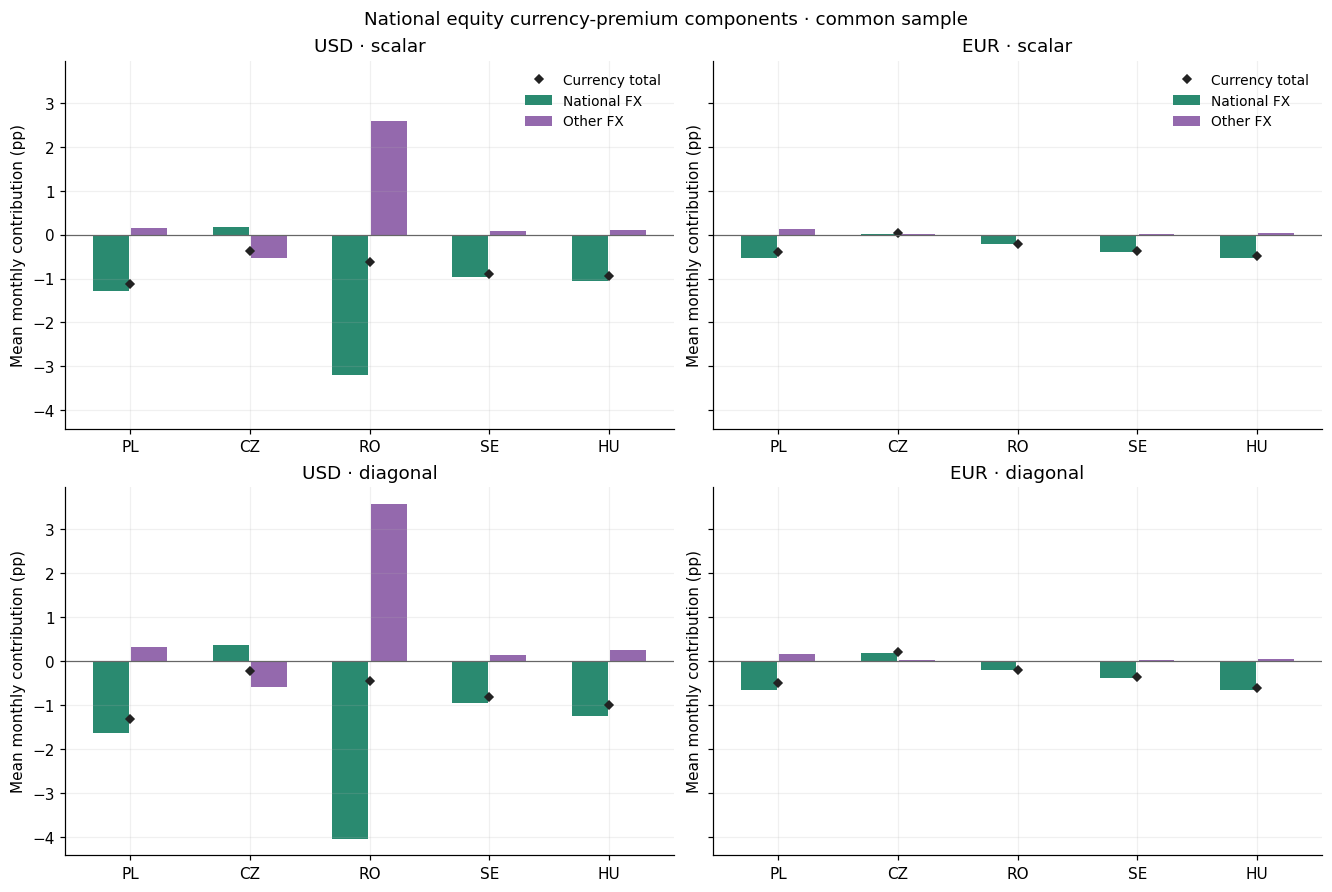

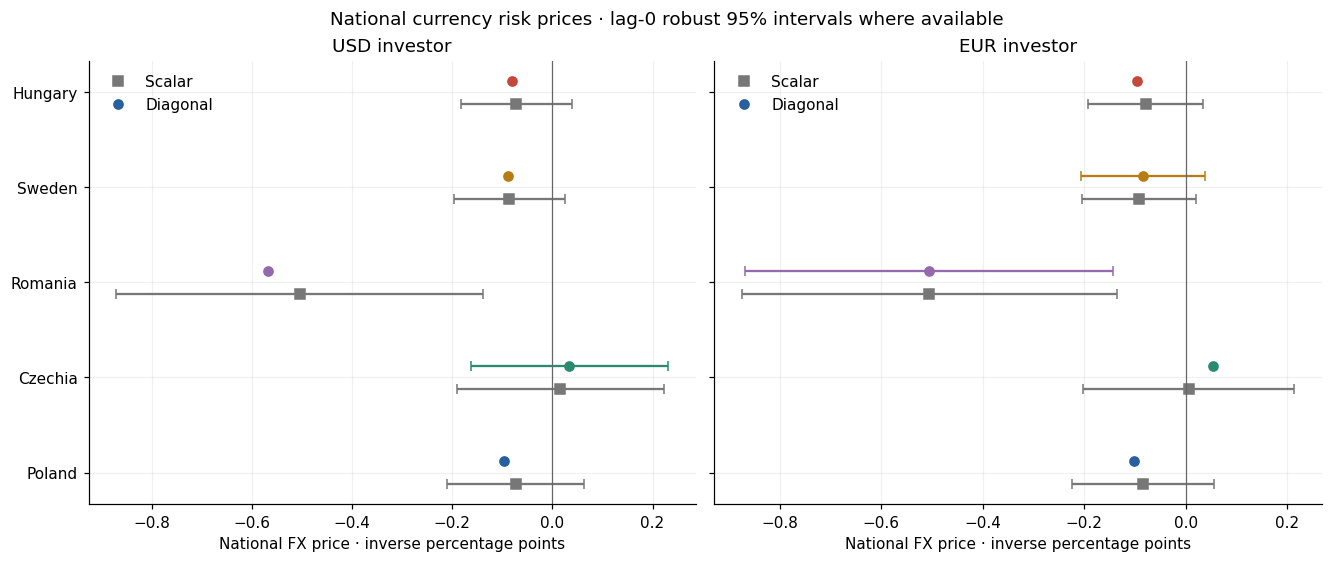

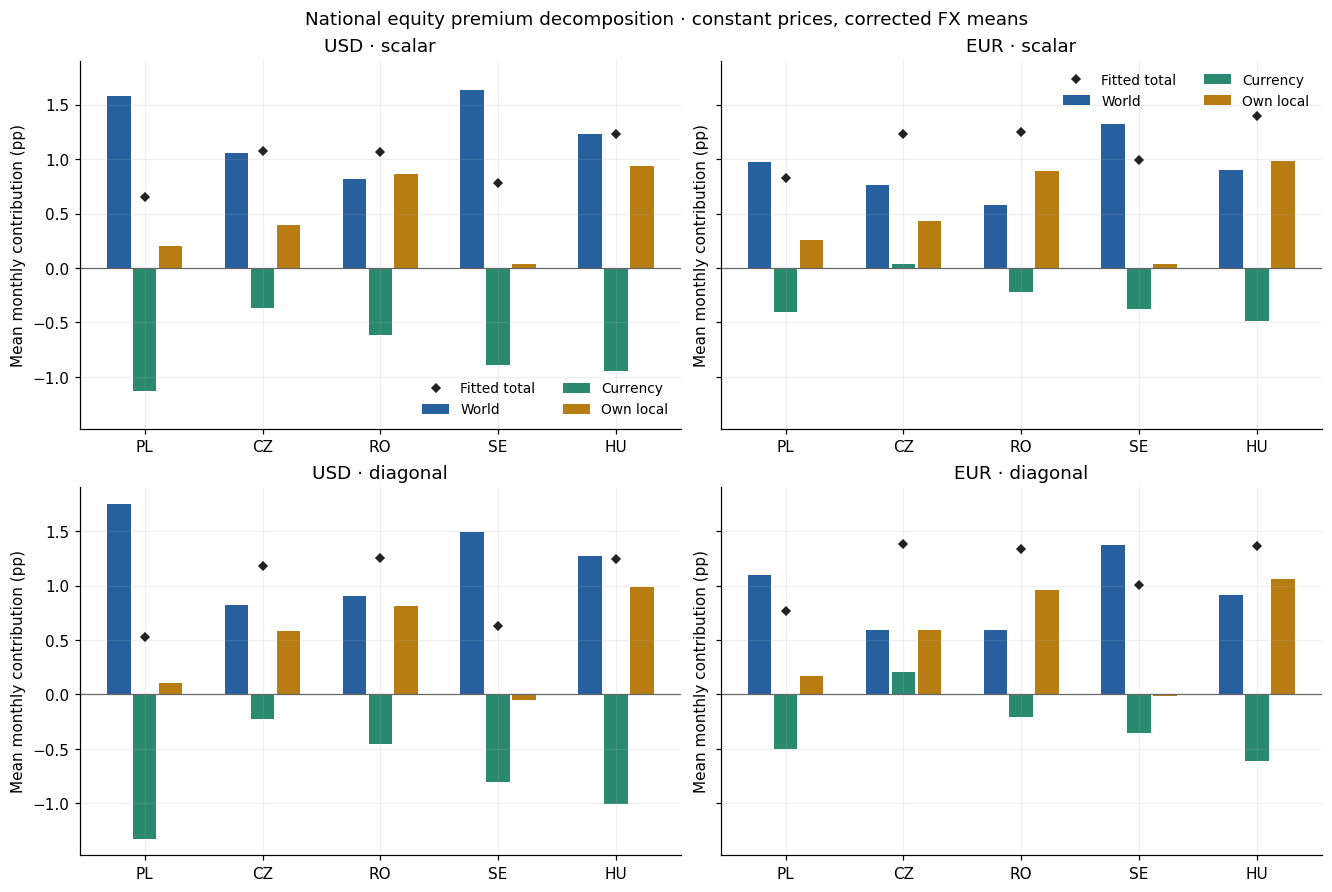

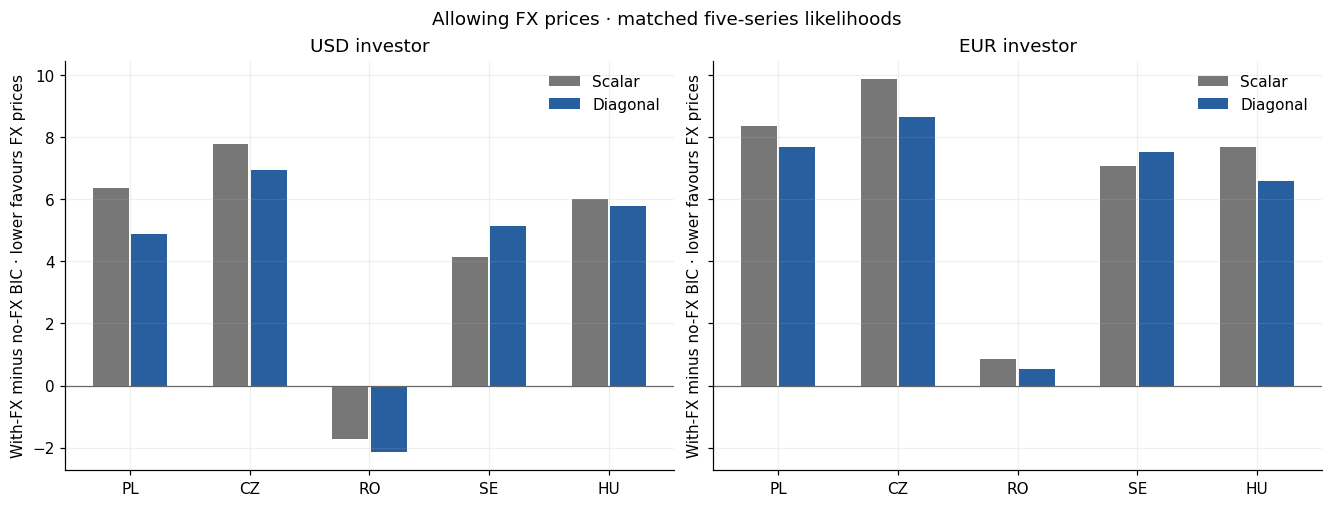

In [7]:
premium_rows, premium_summary_rows, summary_rows, comparison_rows, covariance_rows = [], [], [], [], []
for (country, currency, covariance, model), fit in fits.items():
    f = fit["filter"]
    components = {"world": f["prices"][0]*f["H"][:, 2, 0], "national_FX": f["prices"][3]*f["H"][:, 2, 3],
        "other_FX": f["prices"][4]*f["H"][:, 2, 4], "local": f["prices"][2]*f["H"][:, 2, 2]}
    total = sum(components.values())
    np.testing.assert_allclose(total, f["mu"][:, 2], atol=1e-11, rtol=0)
    tags = {"country": country, "perspective": currency, "covariance": covariance, "model": model}
    for t, month in enumerate(months):
        premium_rows.append({**tags, "month": str(month), **{name+"_premium_pp": values[t] for name, values in components.items()},
            "currency_total_pp": components["national_FX"][t]+components["other_FX"][t], "fitted_mean_pp": total[t],
            "national_FX_price": f["prices"][3], "other_FX_price": f["prices"][4],
            "national_FX_covariance_pp2": f["H"][t, 2, 3], "other_FX_covariance_pp2": f["H"][t, 2, 4],
            "own_variance_pp2": f["H"][t, 2, 2], "world_covariance_pp2": f["H"][t, 2, 0]})
    if model != "with_fx": continue
    choose_test = lambda name, lag: tests.loc[(tests.country == country) & (tests.perspective == currency)
        & (tests.covariance == covariance) & (tests.model == model) & (tests.restriction == name) & (tests.HAC_lag == lag), "p_value"].iloc[0]
    price = price_table.query("country == @country and perspective == @currency and covariance == @covariance and model == 'with_fx' and HAC_lag == 0").set_index("risk")
    r = residuals.query("country == @country and perspective == @currency and covariance == @covariance and model == 'with_fx'")
    c = cross.query("country == @country and perspective == @currency and covariance == @covariance and model == 'with_fx'")
    same = fit_table.query("country == @country and perspective == @currency and covariance == @covariance").set_index("model")
    delta_AIC = same.loc["with_fx", "AIC"]-same.loc["no_fx", "AIC"]
    delta_BIC = same.loc["with_fx", "BIC"]-same.loc["no_fx", "BIC"]
    comparison_rows.append({"country": country, "perspective": currency, "covariance": covariance,
        "delta_AIC_with_vs_no_FX": delta_AIC, "delta_BIC_with_vs_no_FX": delta_BIC,
        "loglik_gain": same.loc["with_fx", "loglik"]-same.loc["no_fx", "loglik"]})
    summary_rows.append({"country": country, "name": NAMES[country], "perspective": currency, "covariance": covariance, "months": len(months),
        "world_price": f["prices"][0], "national_local_price": f["prices"][2], "national_FX_price": f["prices"][3], "other_FX_price": f["prices"][4],
        "national_FX_price_p_QML": price.loc["National FX", "p_value"], "other_FX_price_p_QML": price.loc["Other FX", "p_value"],
        "FX_joint_p_QML": choose_test("FX prices jointly zero", 0), "FX_joint_p_HAC12": choose_test("FX prices jointly zero", 12),
        "mean_national_FX_premium_pp": components["national_FX"].mean(), "mean_other_FX_premium_pp": components["other_FX"].mean(),
        "mean_currency_total_pp": (components["national_FX"]+components["other_FX"]).mean(),
        "mean_world_premium_pp": components["world"].mean(), "mean_local_premium_pp": components["local"].mean(), "mean_fitted_premium_pp": total.mean(),
        "mean_observed_excess_pp": fit["y"][:, 2].mean(), "delta_AIC_with_vs_no_FX": delta_AIC, "delta_BIC_with_vs_no_FX": delta_BIC,
        "numerical_inference_ready": fit["inference"]["estimates"][0]["ready"], "inference_reason": fit["inference"]["estimates"][0]["reason"],
        "mean_flags_raw_5pct": int(r.LB_z_p.lt(.05).sum()), "mean_flags_holm_5pct": int(r.LB_z_p_holm.lt(.05).sum()),
        "variance_flags_raw_5pct": int((r.LB_z_squared_p.lt(.05) | r.ARCH_LM_p.lt(.05)).sum()),
        "variance_flags_holm_5pct": int((r.LB_z_squared_p_holm.lt(.05) | r.ARCH_LM_p_holm.lt(.05)).sum()),
        "cross_flags_raw_5pct": int(c.LB_product_p.lt(.05).sum()), "cross_flags_holm_5pct": int(c.LB_product_p_holm.lt(.05).sum())})
    for name, values in {**components, "currency_total": components["national_FX"]+components["other_FX"], "total": total}.items():
        premium_summary_rows.append({**tags, "component": name, "mean_monthly_pp": values.mean(), "sd_monthly_pp": values.std(ddof=1)})
for (country, currency, model), g in fit_table.groupby(["country", "perspective", "model"]):
    g = g.set_index("covariance")
    covariance_rows.append({"country": country, "perspective": currency, "model": model,
        "delta_AIC_diagonal_vs_scalar": g.loc["diagonal", "AIC"]-g.loc["scalar", "AIC"],
        "delta_BIC_diagonal_vs_scalar": g.loc["diagonal", "BIC"]-g.loc["scalar", "BIC"]})
premiums, premium_summary, summary, comparison, covariance_comparison = map(pd.DataFrame,
    [premium_rows, premium_summary_rows, summary_rows, comparison_rows, covariance_rows])
figure_files = []
def save_plot(name):
    plt.savefig(OUT/name, dpi=170, bbox_inches="tight", metadata={"Software": "Regional currency notebook 23"})
    figure_files.append(name); plt.show(); plt.close()

fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharey=True, layout="constrained")
for row, covariance in enumerate(COVARIANCES):
    for col, currency in enumerate(CURRENCIES):
        ax = axes[row, col]
        s = summary.query("perspective == @currency and covariance == @covariance").set_index("country").loc[list(NAMES)]
        x = np.arange(5)
        ax.bar(x-.16, s.mean_national_FX_premium_pp, width=.3, color="#2a8a70", label="National FX")
        ax.bar(x+.16, s.mean_other_FX_premium_pp, width=.3, color="#9469ad", label="Other FX")
        ax.plot(x, s.mean_currency_total_pp, "D", color="#222222", ms=4, label="Currency total")
        ax.axhline(0, color="#666666", lw=.8)
        ax.set(xticks=x, xticklabels=list(NAMES), title=f"{currency} · {covariance}", ylabel="Mean monthly contribution (pp)")
        if row == 0: ax.legend(frameon=False, fontsize=9)
fig.suptitle("National equity currency-premium components · common sample")
save_plot("01_currency_premiums.png")

fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True, layout="constrained")
for ax, currency in zip(axes, CURRENCIES):
    for covariance, offset, marker in [("scalar", -.12, "s"), ("diagonal", .12, "o")]:
        p = price_table.query("model == 'with_fx' and risk == 'National FX' and HAC_lag == 0 and perspective == @currency and covariance == @covariance").set_index("country")
        for i, country in enumerate(NAMES):
            value, color = p.loc[country], "#777777" if covariance == "scalar" else COLORS[country]
            ax.plot(value.estimate, i+offset, marker, color=color, label=covariance.capitalize() if i == 0 else None)
            if value.inference_ready: ax.errorbar(value.estimate, i+offset, xerr=1.96*value.robust_se, color=color, capsize=3)
    ax.axvline(0, color="#666666", lw=.8)
    ax.set(yticks=range(5), yticklabels=list(NAMES.values()), title=f"{currency} investor", xlabel="National FX price · inverse percentage points")
    ax.legend(frameon=False)
fig.suptitle("National currency risk prices · lag-0 robust 95% intervals where available")
save_plot("02_national_FX_prices.png")

fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharey=True, layout="constrained")
for row, covariance in enumerate(COVARIANCES):
    for col, currency in enumerate(CURRENCIES):
        ax = axes[row, col]
        s = summary.query("perspective == @currency and covariance == @covariance").set_index("country").loc[list(NAMES)]
        x = np.arange(5)
        for offset, field, label, color in [(-.22, "mean_world_premium_pp", "World", "#285f9e"),
                (0., "mean_currency_total_pp", "Currency", "#2a8a70"), (.22, "mean_local_premium_pp", "Own local", "#b77d13")]:
            ax.bar(x+offset, s[field], width=.2, label=label, color=color)
        ax.plot(x, s.mean_fitted_premium_pp, "D", color="#222222", ms=4, label="Fitted total")
        ax.axhline(0, color="#666666", lw=.8)
        ax.set(xticks=x, xticklabels=list(NAMES), title=f"{currency} · {covariance}", ylabel="Mean monthly contribution (pp)")
        if row == 0: ax.legend(frameon=False, fontsize=9, ncol=2)
fig.suptitle("National equity premium decomposition · constant prices, corrected FX means")
save_plot("03_full_premium_decomposition.png")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True, layout="constrained")
for ax, currency in zip(axes, CURRENCIES):
    x = np.arange(5)
    for covariance, offset, color in [("scalar", -.16, "#777777"), ("diagonal", .16, "#285f9e")]:
        s = summary.query("perspective == @currency and covariance == @covariance").set_index("country").loc[list(NAMES)]
        ax.bar(x+offset, s.delta_BIC_with_vs_no_FX, width=.3, label=covariance.capitalize(), color=color)
    ax.axhline(0, color="#666666", lw=.8)
    ax.set(xticks=x, xticklabels=list(NAMES), title=f"{currency} investor", ylabel="With-FX minus no-FX BIC · lower favours FX prices")
    ax.legend(frameon=False)
fig.suptitle("Allowing FX prices · matched five-series likelihoods")
save_plot("04_FX_pricing_BIC.png")

## 7. Final common-sample comparison and reproducibility

Read prices, individual/joint tests, premium magnitudes, numerical inference and residual adequacy
together. Retain scalar as a parsimonious reference and diagonal as sensitivity. A negative national
FX price may produce a negative equity premium term when covariance is positive, but it does not
establish an economic drag from hedging. Actual hedged-return comparisons require forward/carry,
implementation and transaction-cost information. No such investment comparison is estimated here.

This notebook completes **constant** world/local/currency pricing for all five countries under both
covariance models. Later time-varying prices require their own instrument audit; no inference is
promised merely from adding that flexibility. Preserve unavailable results as well as successful ones.

In [8]:
display(summary.set_index(["name", "perspective", "covariance"])[["national_FX_price", "other_FX_price",
    "mean_national_FX_premium_pp", "mean_other_FX_premium_pp", "FX_joint_p_QML", "FX_joint_p_HAC12",
    "delta_BIC_with_vs_no_FX", "numerical_inference_ready"]].round(5))
display(summary.set_index(["name", "perspective", "covariance"])[["inference_reason", "mean_flags_holm_5pct",
    "variance_flags_holm_5pct", "cross_flags_holm_5pct"]])
tables = {"input_audit.csv": input_audit, "implementation_checks.csv": checks, "starting_points.csv": starts_table,
    "fit_summary.csv": fit_table, "risk_prices.csv": price_table, "restriction_tests.csv": tests, "dynamics.csv": dynamics,
    "inference_audit.csv": inference_audit, "parameter_bounds.csv": boundary_audit, "residual_diagnostics.csv": residuals,
    "cross_covariance_diagnostics.csv": cross, "premium_components.csv": premiums, "premium_summary.csv": premium_summary,
    "FX_model_comparison.csv": comparison, "covariance_comparison.csv": covariance_comparison, "common_comparison.csv": summary}
for name, frame in tables.items(): frame.to_csv(OUT/name, index=False, float_format="%.17g", lineterminator="\n")
parameter_files, fit_files = [], []
for (country, currency, covariance, model), fit in fits.items():
    name = f"parameters_{country}_{currency}_{covariance}_{model}.npz"
    f = fit["filter"]
    np.savez(OUT/name, theta=fit["theta"], H=f["H"], mu=f["mu"], errors=f["errors"], scores=f["scores"],
        target=f["target"], intercept=f["intercept"], Hessian=fit["inference"]["Hessian"],
        **{f"covariance_HAC{h}": e["covariance"] for h, e in fit["inference"]["estimates"].items()})
    parameter_files.append(name); fit_files.append(f"fit_{country}_{currency}_{covariance}_{model}.json")
_, after_hashes = verify_inputs()
assert input_hashes == after_hashes and engine_hashes == {name: sha((ROOT/name).read_bytes()) for name in engine_hashes}
outputs = [*tables, *figure_files, *parameter_files, *fit_files]
metadata = {"notebook": "23_regional_currency_risk.ipynb", "model_version": MODEL_VERSION, "engines": engine_hashes,
    "previous_manifest_sha256": PREVIOUS_MANIFEST_SHA, "first": str(months[0]), "last": str(months[-1]),
    "observations_per_fit": len(months), "estimated_fits": len(fits), "input_locks": LOCK_HASHES, "input_file_hashes": input_hashes,
    "settings": {"START_DYNAMICS": START_DYNAMICS, "MAX_ITER": MAX_ITER, "TEST_LAGS": TEST_LAGS, "HAC_LAGS": HAC_LAGS},
    "series_order": ASSETS, "local_currencies": LOCAL_CURRENCIES, "python": sys.executable,
    "python_version": platform.python_version(), "packages": versions,
    "outputs": {name: sha((OUT/name).read_bytes()) for name in outputs},
    "notes": ["Same 144 frozen months for five countries and both USD/EUR; scalar and diagonal covariance",
        "Corrected priced FX means; no VAR or FX intercepts; zero equity alphas; constant risk prices",
        "No-FX fixes both FX prices in all five means; two nested price restrictions",
        "Spot log FX measurement; no manufactured deposit/forward returns or hedging-cost conclusion",
        "KKT optimizer checks; bound/curvature inference suppressed; QML and fixed score-HAC 3/6/12"]}
(OUT/"estimation_manifest.json").write_text(json.dumps(metadata, indent=2, sort_keys=True)+"\n")
unready = int((~summary.numerical_inference_ready).sum())
display(Markdown(f"**Completed:** {len(fits)} joint five-series fits on **{months[0]}–{months[-1]}**, "
    f"{len(months)} months each, in base. **{unready}/20** with-FX systems have suppressed primary inference. "
    f"Saved {len(tables)} tables, {len(figure_files)} charts and all fitted arrays in `{OUT.relative_to(ROOT)}`. "
    "Frozen inputs and all previous model results remain unchanged. Read the inference and diagnostic flags before economic conclusions."))

national_FX_price  other_FX_price  \
name    perspective covariance                                      
Hungary USD         scalar               -0.07261         0.01600   
                    diagonal             -0.08142         0.03330   
        EUR         scalar               -0.07869        -0.01684   
                    diagonal             -0.09699        -0.01680   
Poland  USD         scalar               -0.07346         0.01472   
                    diagonal             -0.09637         0.03274   
        EUR         scalar               -0.08413        -0.02570   
                    diagonal             -0.10169        -0.02938   
Czechia USD         scalar                0.01611        -0.08088   
                    diagonal              0.03398        -0.08714   
        EUR         scalar                0.00533        -0.00941   
                    diagonal              0.05402        -0.01014   
Romania USD         scalar               -0.50501         0.44126   
                    diagonal             -0.56907         0.52387   
        EUR         scalar               -0.50539        -0.00077   
                    diagonal             -0.50570        -0.00336   
Sweden  USD         scalar               -0.08591         0.01229   
                    diagonal             -0.08916         0.02397   
        EUR         scalar               -0.09145        -0.01141   
                    diagonal             -0.08461        -0.01211   

                                mean_national_FX_premium_pp  \
name    perspective covariance                                
Hungary USD         scalar                         -1.05843   
                    diagonal                       -1.24967   
        EUR         scalar                         -0.52948   
                    diagonal                       -0.65476   
Poland  USD         scalar                         -1.27270   
                    diagonal                       -1.64772   
        EUR         scalar                         -0.53870   
                    diagonal                       -0.65813   
Czechia USD         scalar                          0.17199   
                    diagonal                        0.36843   
        EUR         scalar                          0.01806   
                    diagonal                        0.18110   
Romania USD         scalar                         -3.19571   
                    diagonal                       -4.04125   
        EUR         scalar                         -0.22164   
                    diagonal                       -0.21371   
Sweden  USD         scalar                         -0.97055   
                    diagonal                       -0.94524   
        EUR         scalar                         -0.39455   
                    diagonal                       -0.37551   

                                mean_other_FX_premium_pp  FX_joint_p_QML  \
name    perspective covariance                                             
Hungary USD         scalar                       0.11303         0.17067   
                    diagonal                     0.24084             NaN   
        EUR         scalar                       0.04328         0.39499   
                    diagonal                     0.04037             NaN   
Poland  USD         scalar                       0.14462         0.18293   
                    diagonal                     0.32375             NaN   
        EUR         scalar                       0.13614         0.49562   
                    diagonal                     0.15337             NaN   
Czechia USD         scalar                      -0.53776         0.36394   
                    diagonal                    -0.59784         0.40821   
        EUR         scalar                       0.01974         0.97097   
                    diagonal                     0.02169             NaN   
Romania USD         scalar                       2.57980      

inference_reason  \
name    perspective covariance                                               
Hungary USD         scalar                               numerically ready   
                    diagonal    parameter bound; ill-conditioned curvature   
        EUR         scalar                               numerically ready   
                    diagonal    parameter bound; ill-conditioned curvature   
Poland  USD         scalar                               numerically ready   
                    diagonal    parameter bound; ill-conditioned curvature   
        EUR         scalar                               numerically ready   
                    diagonal    parameter bound; ill-conditioned curvature   
Czechia USD         scalar                               numerically ready   
                    diagonal                             numerically ready   
        EUR         scalar                               numerically ready   
                    diagonal    parameter bound; ill-conditioned curvature   
Romania USD         scalar                               numerically ready   
                    diagonal                               parameter bound   
        EUR         scalar                               numerically ready   
                    diagonal                             numerically ready   
Sweden  USD         scalar                               numerically ready   
                    diagonal    parameter bound; ill-conditioned curvature   
        EUR         scalar                               numerically ready   
                    diagonal                             numerically ready   

                                mean_flags_holm_5pct  \
name    perspective covariance                         
Hungary USD         scalar                         0   
                    diagonal                       0   
        EUR         scalar                         0   
                    diagonal                       0   
Poland  USD         scalar                         0   
                    diagonal                       0   
        EUR         scalar                         0   
                    diagonal                       0   
Czechia USD         scalar                         0   
                    diagonal                       0   
        EUR         scalar                         0   
                    diagonal                       0   
Romania USD         scalar                         0   
                    diagonal                       0   
        EUR         scalar                         0   
                    diagonal                       0   
Sweden  USD         scalar                         0   
                    diagonal                       0   
        EUR         scalar                         0   
                    diagonal                       0   

                                variance_flags_holm_5pct  \
name    perspective covariance                             
Hungary USD         scalar                             0   
                    diagonal                           0   
        EUR         scalar                             0   
                    diagonal                           0   
Poland  USD         scalar                             0   
                    diagonal                           0   
        EUR         scalar                             1   
                    diagonal                           1   
Czechia USD         scalar                             0   
                    diagonal                           0   
        EUR         scalar                             0   
                    diagonal                           0   
Romania USD         scalar                             0   
                    diagonal                           0   
        EUR         scalar                             0   
                    diagonal                           0   
Sweden  USD         scalar  

**Completed:** 40 joint five-series fits on **2014-10–2026-09**, 144 months each, in base. **7/20** with-FX systems have suppressed primary inference. Saved 16 tables, 4 charts and all fitted arrays in `output/23_regional_currency_risk/2014-10_2026-09`. Frozen inputs and all previous model results remain unchanged. Read the inference and diagnostic flags before economic conclusions.